In [28]:
import numpy as np
import matplotlib.pyplot as plt
import astrotools.nbody.drag as d

#Section a below:

dv = 0.0
st = 10**6
r_cap = 0.05
dx0 = 0.02
x0 = np.arange(-3, 3, dx0)

flag = []
times = []
positions = []
cap_pos = []

for x in x0:
    y_0 = d.initial_state(x, st, dv)
    cap, time, pos = d.encounter(d.rk4_step, d.hill_drag_derivs, y_0, r_cap, st, dv) #encounter modified to now take st and dv for use in stepper and hill_derivatives
    flag.append(cap)
    times.append(time)
    positions.append(pos)
    if cap == True: cap_pos.append(np.abs(y_0[3]))

#captured, times, and positions are now lists of booleans, array of time, array of positions for each particle at starting position x0

#find range of x0 where particles are captured. To do this, I'll find the first value where it is captured and the last. might need to check if there are any falses inside the boundary.

captured = [i for i,x in enumerate(flag) if x == True] #all indexes where pebble is captured
x_cap = [x0[i] for i in range(len(flag)) if i in set(captured)] #this shows all x0 values where the pebbles are captured.
xmax = np.max(x_cap)
xmin = np.min(x_cap)

absv_dx = np.abs(cap_pos) * dx0
Mdot_num = sum(absv_dx)

#sum of all y-velocities that impacted times dx0

Mdot_an = 3 * (3 * st)**(2/3) #accretion rate in terms of sigma_peb-omega_k-r_H^2
print(f'The range of captured pebbles is from {xmin} to {xmax} r$_H$.') 
print(f'The analytical accretion rate = {Mdot_an}.')
print(f'The numerical accretion rate = {Mdot_num}.')

The range of captured pebbles is from -2.2799999999999994 to 2.2800000000000047 r$_H$.
The analytical accretion rate = 62402.51469155708.
The numerical accretion rate = 2.5896000000000026.


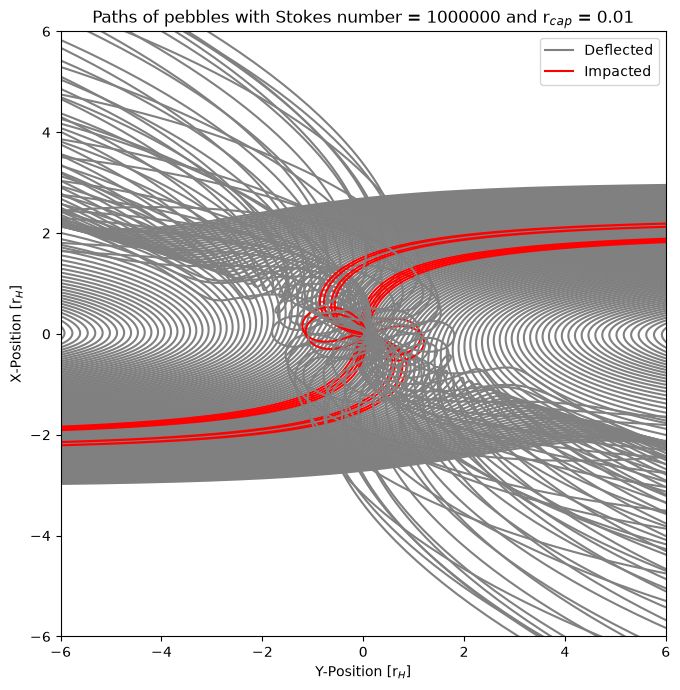

In [6]:
#this cell plots paths of pebbles based on stokes number, x0, dv defined above.

fig, ax = plt.subplots(figsize = (10, 7))
for x in x0:
    y0 = d.initial_state(x, st, dv)
    cap, time, pos = d.encounter(d.rk4_step, d.hill_drag_derivs, y0, r_cap, st, dv) #encounter modified to now take st and dv for use in stepper and hill_derivatives
    if cap == True:
        ax.plot(pos[:,1], pos[:,0], color = 'red')
    else:
        ax.plot(pos[:,1], pos[:,0], color = 'grey')


ax.plot([],[], color = 'grey', label = 'Deflected')
ax.plot([],[], color = 'red', label = 'Impacted')
ax.set_xlim(-6, 6)
ax.set_ylabel(r'X-Position [r$_H$]')
ax.set_xlabel(r'Y-Position [r$_H$]')
ax.set_ylim(-6, 6)
ax.set_title(f'Paths of pebbles with Stokes number = {st} and r$_c$$_a$$_p$ = {r_cap}')
ax.set_aspect('equal')
legend = ax.legend()

plt.tight_layout()
plt.show()